In [1]:
# Descargar y cargar el dataset

import pandas as pd
import numpy as np
import requests
import zipfile
import io
from pathlib import Path

# Crear estructura de carpetas
base = Path("Actividad5")
original = base / "datos" / "datos_ini"
limpio = base / "datos" / "datos_limp"

original.mkdir(parents=True, exist_ok=True)
limpio.mkdir(parents=True, exist_ok=True)

# Descargar dataset original de UCI
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
respuesta = requests.get(url, timeout=120)
respuesta.raise_for_status()

with zipfile.ZipFile(io.BytesIO(respuesta.content)) as externo:
    with zipfile.ZipFile(io.BytesIO(externo.read("bank.zip"))) as interno:
        archivo = interno.read("bank-full.csv")

ruta_original = original / "bank-full.csv"
ruta_original.write_bytes(archivo)

df = pd.read_csv(ruta_original, sep=";")

print("Dimensiones originales:", df.shape)
display(df.head())


Dimensiones originales: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
# Diagnóstico de calidad

print("=== DIAGNÓSTICO INICIAL ===")
print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Valores nulos:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

print("\nTipos de datos:")
print(df.dtypes.value_counts())

print("\nValores 'unknown' por variable:")
for columna in df.select_dtypes(include="object"):
    cantidad = (df[columna] == "unknown").sum()
    if cantidad > 0:
        print(f"{columna}: {cantidad}")

print("\nDistribución de la variable objetivo:")
print(df["y"].value_counts())


=== DIAGNÓSTICO INICIAL ===
Filas: 45211
Columnas: 17
Valores nulos: 0
Filas duplicadas: 0

Tipos de datos:
object    10
int64      7
Name: count, dtype: int64

Valores 'unknown' por variable:
job: 288
education: 1857
contact: 13020
poutcome: 36959

Distribución de la variable objetivo:
y
no     39922
yes     5289
Name: count, dtype: int64


In [3]:
# Limpieza y aplicación de reglas

# Trabajar sobre una copia del dataset original
df_limpio = df.copy()

# Identificar duplicados exactos originales
duplicados_originales = df_limpio.duplicated().sum()

# Eliminar duplicados exactos originales
df_limpio = df_limpio.drop_duplicates().copy()

# Excluir variable que genera fuga de información
df_limpio = df_limpio.drop(columns=["duration"])

# Identificar coincidencias después de quitar duration
coincidencias = df_limpio.duplicated().sum()

# Validar variable objetivo
assert df_limpio["y"].isin(["yes", "no"]).all()

# Validar edades
assert df_limpio["age"].between(18, 100).all()

# Validar que no existan duplicados originales
assert not df.duplicated().sum() - duplicados_originales

# Guardar archivo limpio
ruta_limpia = limpio / "bank_limpio.csv"
df_limpio.to_csv(ruta_limpia, index=False)

# Mostrar resultados
print("=== RESULTADO DE LIMPIEZA ===")
print("Registros originales:", len(df))
print("Duplicados originales eliminados:", duplicados_originales)
print("Registros finales:", len(df_limpio))
print("Columnas finales:", len(df_limpio.columns))
print("Valores nulos:", df_limpio.isna().sum().sum())
print("Coincidencias tras excluir duration:", coincidencias)
print("Archivo guardado:", ruta_limpia)


=== RESULTADO DE LIMPIEZA ===
Registros originales: 45211
Duplicados originales eliminados: 0
Registros finales: 45211
Columnas finales: 16
Valores nulos: 0
Coincidencias tras excluir duration: 16
Archivo guardado: Actividad5/datos/datos_limp/bank_limpio.csv


In [4]:
# Preparar las transformaciones para los modelos

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Variable objetivo y características
X = df_limpio.drop(columns=["y"])
y = df_limpio["y"].map({"no": 0, "yes": 1})

numericas = X.select_dtypes(include=np.number).columns.tolist()
categoricas = X.select_dtypes(exclude=np.number).columns.tolist()

# Pipeline para regresión logística
prep_logistica = ColumnTransformer([
    ("numericas", StandardScaler(), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Pipeline para random forest
prep_forest = ColumnTransformer([
    ("numericas", "passthrough", numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas)
print("Variables predictoras:", X.shape[1])
print("Variable objetivo: y")
print("Transformaciones configuradas correctamente.")


Variables numéricas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Variables predictoras: 15
Variable objetivo: y
Transformaciones configuradas correctamente.


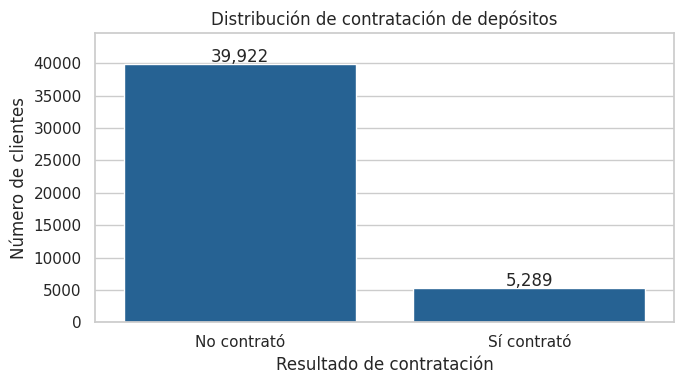

Porcentajes de contratación:
y
no     88.3
yes    11.7
Name: count, dtype: float64


In [5]:
# Distribución de la variable objetivo

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Carpeta para guardar gráficas
graficas = Path("Actividad5/evidencias")
graficas.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

conteo = df_limpio["y"].value_counts().reindex(["no", "yes"])
porcentaje = conteo / conteo.sum() * 100

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=["No contrató", "Sí contrató"],
    y=conteo.values,
    color="#1464A5"
)

for i, valor in enumerate(conteo.values):
    ax.text(i, valor + 300, f"{valor:,}", ha="center")

plt.title("Distribución de contratación de depósitos")
plt.ylabel("Número de clientes")
plt.xlabel("Resultado de contratación")
plt.ylim(0, conteo.max() * 1.12)
plt.tight_layout()
plt.savefig(graficas / "figura4_contratacion.png", dpi=160)
plt.show()

print("Porcentajes de contratación:")
print(porcentaje.round(2))


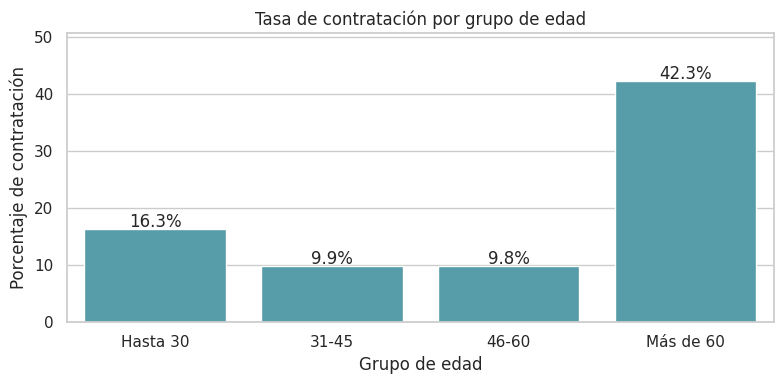

grupo_edad
Hasta 30     16.29
31-45         9.88
46-60         9.78
Más de 60    42.26
Name: y, dtype: float64


In [6]:
# Contratación por grupo de edad

# Crear grupos de edad
df_eda = df_limpio.copy()

df_eda["grupo_edad"] = pd.cut(
    df_eda["age"],
    bins=[0, 30, 45, 60, float("inf")],
    labels=["Hasta 30", "31-45", "46-60", "Más de 60"]
)

# Calcular tasa de contratación por grupo
tasas = (
    df_eda.groupby("grupo_edad", observed=True)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    x=tasas.index.astype(str),
    y=tasas.values,
    color="#49A5B7"
)

for i, valor in enumerate(tasas.values):
    ax.text(i, valor + 0.4, f"{valor:.1f}%", ha="center")

plt.title("Tasa de contratación por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Porcentaje de contratación")
plt.ylim(0, max(tasas.values) * 1.2)
plt.tight_layout()
plt.savefig(graficas / "figura5_edad.png", dpi=160)
plt.show()

print(tasas.round(2))


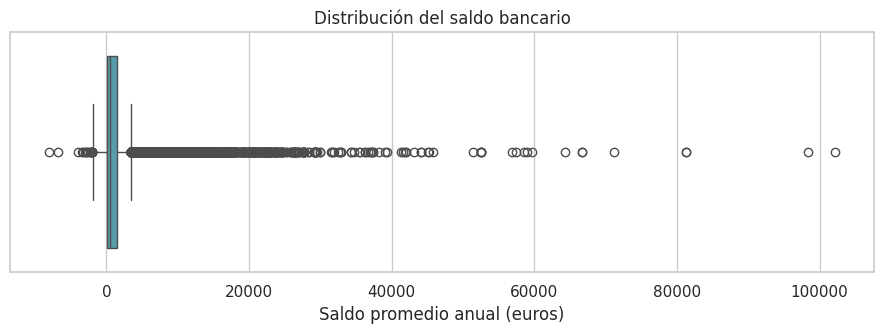

=== ANÁLISIS DEL SALDO ===
Saldo mínimo: -8019
Saldo máximo: 102127
Mediana: 448.0
Valores atípicos (IQR): 4729
Porcentaje atípico: 10.46


In [7]:
# Identificación de valores atípicos

plt.figure(figsize=(9, 3.5))

sns.boxplot(
    x=df_limpio["balance"],
    color="#49A5B7"
)

plt.title("Distribución del saldo bancario")
plt.xlabel("Saldo promedio anual (euros)")
plt.tight_layout()
plt.savefig(graficas / "figura6_saldo.png", dpi=160)
plt.show()

# Identificar valores atípicos con el método IQR
q1 = df_limpio["balance"].quantile(0.25)
q3 = df_limpio["balance"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = (
    (df_limpio["balance"] < limite_inferior) |
    (df_limpio["balance"] > limite_superior)
).sum()

print("=== ANÁLISIS DEL SALDO ===")
print("Saldo mínimo:", df_limpio["balance"].min())
print("Saldo máximo:", df_limpio["balance"].max())
print("Mediana:", df_limpio["balance"].median())
print("Valores atípicos (IQR):", atipicos)
print("Porcentaje atípico:", round(atipicos / len(df_limpio) * 100, 2))


In [8]:
# Crear README.md

from pathlib import Path

base = Path("Actividad5")
base.mkdir(exist_ok=True)

readme = """# Actividad 5 - Machine Learning y MLOps

## Descripción
Predicción de contratación de depósitos bancarios mediante
regresión logística y random forest.

## Dataset
Nombre: Bank Marketing
Fuente: UCI Machine Learning Repository
URL: https://archive.ics.uci.edu/dataset/222/bank+marketing

## Preparación de datos
- 45,211 registros originales.
- 17 columnas originales.
- Sin valores nulos.
- Sin duplicados exactos originales.
- Exclusión de la variable duration.
- Conservación de valores unknown y pdays = -1.
- Dataset preparado: 45,211 registros y 16 columnas.

## Análisis exploratorio
- Contratación positiva: 11.7%.
- Contratación negativa: 88.3%.
- Valores atípicos de balance: 4,729 (10.46%).
- Mayor tasa de contratación por edad: mayores de 60 años.

## Modelos
1. Regresión logística.
2. Random forest.

## Metodología
- Preparación mediante pipelines de scikit-learn.
- Validación cruzada de 5 particiones.
- Optimización mediante GridSearchCV.
- Evaluación con accuracy, precision, recall, F1 y ROC-AUC.
- Registro de experimentos mediante MLflow.

## Estructura
- datos/datos_ini: datos originales.
- datos/datos_limp: datos preparados.
- fuentes: notebook y scripts Python.
- evidencias: gráficas y capturas.
- CHANGELOG.md: historial de cambios.

## Reproducción
Los pasos de instalación y ejecución se completarán
cuando finalice la implementación de los modelos.

## Consideraciones
Proyecto académico basado en datos públicos.
No utiliza información de clientes de BBVA.
"""

(base / "README.md").write_text(readme, encoding="utf-8")

print("README.md creado correctamente")


README.md creado correctamente


In [9]:
# Crear CHANGELOG.md

changelog = """# Historial de cambios - Actividad 5

## Versión 0.1.0 - Preparación inicial

### Incorporado
- Dataset original Bank Marketing.
- Estructura de carpetas del proyecto.
- Diagnóstico de calidad de datos.
- Archivo de datos preparados.
- Análisis exploratorio con tres visualizaciones.
- Configuración inicial de transformadores.

### Resultados
- Registros originales: 45,211.
- Duplicados exactos originales: 0.
- Valores nulos: 0.
- Registros finales: 45,211.
- Columnas finales: 16.
- Coincidencias tras excluir duration: 16.

### Decisiones técnicas
- Se excluyó duration para evitar fuga de información.
- Se conservaron los valores categóricos unknown.
- Se mantuvo pdays = -1 por su significado.
- No se eliminaron automáticamente valores atípicos.
- Se conservaron coincidencias posteriores a la exclusión
  de duration por no demostrar duplicación real.

## Pendiente
- Entrenamiento de modelos.
- Ajuste de hiperparámetros.
- Registro de experimentos en MLflow.
- Evaluación comparativa.
"""

(base / "CHANGELOG.md").write_text(
    changelog, encoding="utf-8"
)

print("CHANGELOG.md creado correctamente")


CHANGELOG.md creado correctamente


In [10]:
# Crear requirements.txt y .gitignore

requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
mlflow
requests
"""

gitignore = """__pycache__/
*.pyc
.ipynb_checkpoints/
mlruns/
mlartifacts/
mlflow.db
.env
"""

(base / "requirements.txt").write_text(
    requirements, encoding="utf-8"
)

(base / ".gitignore").write_text(
    gitignore, encoding="utf-8"
)

(base / "fuentes").mkdir(exist_ok=True)

print("Archivos complementarios creados")


Archivos complementarios creados


In [11]:
# Comprobar archivos

print("=== ESTRUCTURA ACTUAL DEL PROYECTO ===")

for archivo in sorted(base.rglob("*")):
    if archivo.is_file():
        print(archivo)


=== ESTRUCTURA ACTUAL DEL PROYECTO ===
Actividad5/.gitignore
Actividad5/CHANGELOG.md
Actividad5/README.md
Actividad5/datos/datos_ini/bank-full.csv
Actividad5/datos/datos_limp/bank_limpio.csv
Actividad5/evidencias/figura4_contratacion.png
Actividad5/evidencias/figura5_edad.png
Actividad5/evidencias/figura6_saldo.png
Actividad5/requirements.txt


In [12]:
# Descargar el proyecto

import shutil
from google.colab import files

archivo_zip = shutil.make_archive(
    "Actividad5_respaldo", "zip",
    root_dir=".", base_dir="Actividad5"
)

files.download(archivo_zip)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Crear datos_prep.py

%%writefile Actividad5/fuentes/datos_prep.py
import pandas as pd
from pathlib import Path


def preparar_datos(ruta_entrada, ruta_salida):
    """
    Limpia el dataset Bank Marketing y guarda
    una versión preparada para entrenamiento.
    """

    # Cargar dataset original
    df = pd.read_csv(ruta_entrada, sep=";")

    registros_originales = len(df)

    # Identificar y eliminar duplicados exactos
    duplicados = df.duplicated().sum()
    df = df.drop_duplicates().copy()

    # Excluir duration para evitar fuga de información
    df = df.drop(columns=["duration"])

    # Conservar valores unknown y pdays = -1
    # por su significado en el dataset

    # Validar datos
    assert df["y"].isin(["yes", "no"]).all()
    assert df["age"].between(18, 100).all()

    # Crear carpeta de salida
    ruta_salida = Path(ruta_salida)
    ruta_salida.parent.mkdir(
        parents=True, exist_ok=True
    )

    # Guardar dataset preparado
    df.to_csv(ruta_salida, index=False)

    print("=== PREPARACIÓN COMPLETADA ===")
    print("Registros originales:", registros_originales)
    print("Duplicados eliminados:", duplicados)
    print("Registros finales:", len(df))
    print("Columnas finales:", len(df.columns))
    print("Valores nulos:", df.isna().sum().sum())

    return df


if __name__ == "__main__":
    preparar_datos(
        "Actividad5/datos/datos_ini/bank-full.csv",
        "Actividad5/datos/datos_limp/bank_limpio.csv"
    )


Writing Actividad5/fuentes/datos_prep.py


In [14]:
# Comprobar que funciona

!python Actividad5/fuentes/datos_prep.py


=== PREPARACIÓN COMPLETADA ===
Registros originales: 45211
Duplicados eliminados: 0
Registros finales: 45211
Columnas finales: 16
Valores nulos: 0


In [15]:
# datos_prep.py

from google.colab import files

files.download("Actividad5/fuentes/datos_prep.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# repositorio en Colab

!git clone https://github.com/FernandoPTec/Actividad5-Bank-Marketing.git


Cloning into 'Actividad5-Bank-Marketing'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 42 (delta 11), reused 5 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 1.07 MiB | 2.94 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [17]:
# Verificar la conexión

%cd /content/Actividad5-Bank-Marketing

!git status
!git remote -v
!git log -1 --oneline


/content/Actividad5-Bank-Marketing
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
origin	https://github.com/FernandoPTec/Actividad5-Bank-Marketing.git (fetch)
origin	https://github.com/FernandoPTec/Actividad5-Bank-Marketing.git (push)
289e39e (HEAD -> main, origin/main, origin/HEAD) Documentar verificacion de Git y limpieza


In [18]:
# commit desde Colab

from pathlib import Path

archivo = Path("CHANGELOG.md")

with archivo.open("a", encoding="utf-8") as f:
    f.write(
        "\n## Verificación de Git\n"
        "- Repositorio clonado y conexión remota verificada.\n"
        "- Script de limpieza ejecutado correctamente.\n"
    )

print("CHANGELOG.md actualizado")


CHANGELOG.md actualizado


In [19]:
# registramos el cambio

!git config user.name "FernandoPTec"
!git config user.email "al07182830@tecmilenio.mx"

!git add CHANGELOG.md
!git commit -m "Documentar verificacion de Git y limpieza"
!git status


[main 96e0815] Documentar verificacion de Git y limpieza
 1 file changed, 4 insertions(+)
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [20]:
# Verificar GitHub CLI

!gh --version


gh version 2.102.0 (2026-09-30)
https://github.com/cli/cli/releases/tag/v2.102.0


In [21]:
# Regresar al repositorio
%cd /content/Actividad5-Bank-Marketing

!git status


/content/Actividad5-Bank-Marketing
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [22]:
# Publicar el commit utilizando tu token

import os
import subprocess
import tempfile
from getpass import getpass

# Solicitar token sin mostrarlo
token = getpass("Pega tu token de GitHub: ")

# Crear un archivo temporal para autenticación
with tempfile.TemporaryDirectory() as carpeta:
    askpass = os.path.join(carpeta, "askpass.sh")

    with open(askpass, "w") as f:
        f.write('#!/bin/sh\n')
        f.write('case "$1" in\n')
        f.write('  *Username*) echo "x-access-token" ;;\n')
        f.write('  *Password*) printf "%s\\n" "$GITHUB_TOKEN" ;;\n')
        f.write('esac\n')

    os.chmod(askpass, 0o700)

    entorno = os.environ.copy()
    entorno["GIT_ASKPASS"] = askpass
    entorno["GIT_TERMINAL_PROMPT"] = "0"
    entorno["GITHUB_TOKEN"] = token

    resultado = subprocess.run(
        ["git", "push", "origin", "main"],
        cwd="/content/Actividad5-Bank-Marketing",
        env=entorno,
        capture_output=True,
        text=True
    )

    print("=== RESULTADO DE GIT PUSH ===")
    print("Código de salida:", resultado.returncode)
    print(resultado.stdout)
    print(resultado.stderr.replace(token, "[OCULTO]"))

# Eliminar la variable con el token
del token


Pega tu token de GitHub: ··········
=== RESULTADO DE GIT PUSH ===
Código de salida: 0

To https://github.com/FernandoPTec/Actividad5-Bank-Marketing.git
   289e39e..96e0815  main -> main



In [23]:
#Verificar la sincronización

!git status
!git log -2 --oneline


On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
96e0815 (HEAD -> main, origin/main, origin/HEAD) Documentar verificacion de Git y limpieza
289e39e Documentar verificacion de Git y limpieza


In [24]:
# Cargar datos y preparar variables

import pandas as pd
import numpy as np
from pathlib import Path

ruta = Path(
    "/content/Actividad5-Bank-Marketing/"
    "datos/datos_limp/bank_limpio.csv"
)

df_modelo = pd.read_csv(ruta)

# Separar características y variable objetivo
X = df_modelo.drop(columns=["y"])
y = df_modelo["y"].map({"no": 0, "yes": 1})

# Verificar datos
assert y.notna().all()
assert "duration" not in X.columns

print("=== DATOS PARA ENTRENAMIENTO ===")
print("Registros:", len(df_modelo))
print("Variables predictoras:", X.shape[1])
print("Variable objetivo:", "y")
print("Clases:", y.value_counts().to_dict())


=== DATOS PARA ENTRENAMIENTO ===
Registros: 45211
Variables predictoras: 15
Variable objetivo: y
Clases: {0: 39922, 1: 5289}


In [25]:
# División entrenamiento-prueba

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== DIVISIÓN DE DATOS ===")
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nPorcentaje de contratación:")
print("Entrenamiento:", round(y_train.mean()*100, 2), "%")
print("Prueba:", round(y_test.mean()*100, 2), "%")


=== DIVISIÓN DE DATOS ===
Entrenamiento: (36168, 15)
Prueba: (9043, 15)

Porcentaje de contratación:
Entrenamiento: 11.7 %
Prueba: 11.7 %


In [26]:
# Crear pipelines

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Identificar variables
numericas = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categoricas = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocesamiento de regresión logística
prep_logistica = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Preprocesamiento de random forest
prep_forest = ColumnTransformer([
    ("num", "passthrough", numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

# Modelo 1
modelo_logistica = Pipeline([
    ("preprocesamiento", prep_logistica),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Modelo 2
modelo_forest = Pipeline([
    ("preprocesamiento", prep_forest),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Modelos configurados correctamente")
print("Variables numéricas:", len(numericas))
print("Variables categóricas:", len(categoricas))


Modelos configurados correctamente
Variables numéricas: 6
Variables categóricas: 9


In [27]:
# Entrenamiento y validación cruzada

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

modelos = {
    "Regresión logística": modelo_logistica,
    "Random forest": modelo_forest
}

resultados = []

for nombre, modelo in modelos.items():

    print(f"\nEntrenando: {nombre}")

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=2,
        error_score="raise"
    )

    fila = {"Modelo": nombre}

    for metrica in metricas:
        valores = scores[f"test_{metrica}"]
        fila[metrica] = valores.mean()
        fila[f"{metrica}_std"] = valores.std()

    resultados.append(fila)

    print("Validación completada")

tabla_resultados = pd.DataFrame(resultados)

display(
    tabla_resultados[
        ["Modelo", "accuracy", "precision",
         "recall", "f1", "roc_auc"]
    ].round(4)
)



Entrenando: Regresión logística
Validación completada

Entrenando: Random forest
Validación completada


,Modelo,accuracy,precision,recall,f1,roc_auc
0,Regresión logística,0.8922,0.6446,0.1749,0.2749,0.7628
1,Random forest,0.8917,0.5978,0.2252,0.3271,0.7789


In [28]:
# Exportar tabla de resultados

ruta_resultados = Path(
    "/content/Actividad5-Bank-Marketing/evidencias"
)

ruta_resultados.mkdir(
    parents=True, exist_ok=True
)

tabla_resultados.to_csv(
    ruta_resultados / "validacion_inicial.csv",
    index=False
)

print("Resultados de validación guardados correctamente")


Resultados de validación guardados correctamente


In [29]:
# Validacion inicial

from google.colab import files

files.download(
    "/content/Actividad5-Bank-Marketing/evidencias/validacion_inicial.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Configurar búsqueda de regresión logística

from sklearn.model_selection import GridSearchCV

# Combinaciones de hiperparámetros
parametros_logistica = {
    "clasificador__C": [0.1, 1, 10],
    "clasificador__class_weight": [None, "balanced"]
}

grid_logistica = GridSearchCV(
    estimator=modelo_logistica,
    param_grid=parametros_logistica,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1,
    return_train_score=True,
    refit=True,
    error_score="raise"
)

print("Iniciando Grid Search: Regresión logística")

grid_logistica.fit(X_train, y_train)

print("\n=== RESULTADOS REGRESIÓN LOGÍSTICA ===")
print("Mejores parámetros:", grid_logistica.best_params_)
print("Mejor F1:", round(grid_logistica.best_score_, 4))


Iniciando Grid Search: Regresión logística
Fitting 5 folds for each of 6 candidates, totalling 30 fits

=== RESULTADOS REGRESIÓN LOGÍSTICA ===
Mejores parámetros: {'clasificador__C': 1, 'clasificador__class_weight': 'balanced'}
Mejor F1: 0.3726


In [31]:
# Configurar búsqueda de random forest

parametros_forest = {
    "clasificador__n_estimators": [100, 200],
    "clasificador__max_depth": [10, 20],
    "clasificador__min_samples_leaf": [1, 5],
    "clasificador__class_weight": [None, "balanced"]
}

grid_forest = GridSearchCV(
    estimator=modelo_forest,
    param_grid=parametros_forest,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1,
    return_train_score=True,
    refit=True,
    error_score="raise"
)

print("Iniciando Grid Search: Random forest")

grid_forest.fit(X_train, y_train)

print("\n=== RESULTADOS RANDOM FOREST ===")
print("Mejores parámetros:", grid_forest.best_params_)
print("Mejor F1:", round(grid_forest.best_score_, 4))


Iniciando Grid Search: Random forest
Fitting 5 folds for each of 16 candidates, totalling 80 fits

=== RESULTADOS RANDOM FOREST ===
Mejores parámetros: {'clasificador__class_weight': 'balanced', 'clasificador__max_depth': 20, 'clasificador__min_samples_leaf': 5, 'clasificador__n_estimators': 200}
Mejor F1: 0.4702


In [32]:
# Tabla comparativa

import pandas as pd

comparacion = pd.DataFrame({
    "Modelo": [
        "Regresión logística",
        "Random forest"
    ],
    "F1 inicial": [
        tabla_resultados.loc[
            tabla_resultados["Modelo"] == "Regresión logística",
            "f1"
        ].iloc[0],
        tabla_resultados.loc[
            tabla_resultados["Modelo"] == "Random forest",
            "f1"
        ].iloc[0]
    ],
    "F1 GridSearchCV": [
        grid_logistica.best_score_,
        grid_forest.best_score_
    ]
})

comparacion["Diferencia F1"] = (
    comparacion["F1 GridSearchCV"] -
    comparacion["F1 inicial"]
)

print("=== COMPARACIÓN DE OPTIMIZACIÓN ===")
display(comparacion.round(4))


=== COMPARACIÓN DE OPTIMIZACIÓN ===


,Modelo,F1 inicial,F1 GridSearchCV,Diferencia F1
0,Regresión logística,0.2749,0.3726,0.0977
1,Random forest,0.3271,0.4702,0.1432


In [33]:
# Guardar los resultados y modelos

from pathlib import Path
import joblib

ruta_evidencias = Path(
    "/content/Actividad5-Bank-Marketing/evidencias"
)

ruta_modelos = Path(
    "/content/Actividad5-Bank-Marketing/modelos"
)

ruta_evidencias.mkdir(parents=True, exist_ok=True)
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Resultados completos de cada búsqueda
pd.DataFrame(grid_logistica.cv_results_).to_csv(
    ruta_evidencias / "grid_logistica.csv",
    index=False
)

pd.DataFrame(grid_forest.cv_results_).to_csv(
    ruta_evidencias / "grid_forest.csv",
    index=False
)

# Comparación de desempeño
comparacion.to_csv(
    ruta_evidencias / "comparacion_gridsearch.csv",
    index=False
)

# Guardar mejores modelos
joblib.dump(
    grid_logistica.best_estimator_,
    ruta_modelos / "modelo_logistica.pkl"
)

joblib.dump(
    grid_forest.best_estimator_,
    ruta_modelos / "modelo_forest.pkl"
)

print("Resultados y modelos guardados correctamente")


Resultados y modelos guardados correctamente


In [34]:
# descargar los resultados y los modelos

import shutil
from google.colab import files

ruta_base = "/content/Actividad5-Bank-Marketing"

respaldo = shutil.make_archive(
    "/content/Actividad5_modelos_optimizados",
    "zip",
    root_dir=ruta_base,
    base_dir="modelos"
)

files.download(respaldo)

print("Respaldo de modelos generado correctamente")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Respaldo de modelos generado correctamente


In [35]:
# Evaluación con datos de prueba

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Modelos optimizados
modelos_finales = {
    "Regresión logística": grid_logistica.best_estimator_,
    "Random forest": grid_forest.best_estimator_
}

resultados_prueba = []
predicciones = {}

for nombre, modelo in modelos_finales.items():

    # Predicciones sobre datos no utilizados en entrenamiento
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    predicciones[nombre] = y_pred

    resultados_prueba.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tabla_prueba = pd.DataFrame(resultados_prueba)

print("=== EVALUACIÓN FINAL EN DATOS DE PRUEBA ===")
display(tabla_prueba.round(4))


=== EVALUACIÓN FINAL EN DATOS DE PRUEBA ===


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión logística,0.7548,0.2662,0.6238,0.3732,0.7722
1,Random forest,0.8611,0.4273,0.5501,0.4810,0.8031


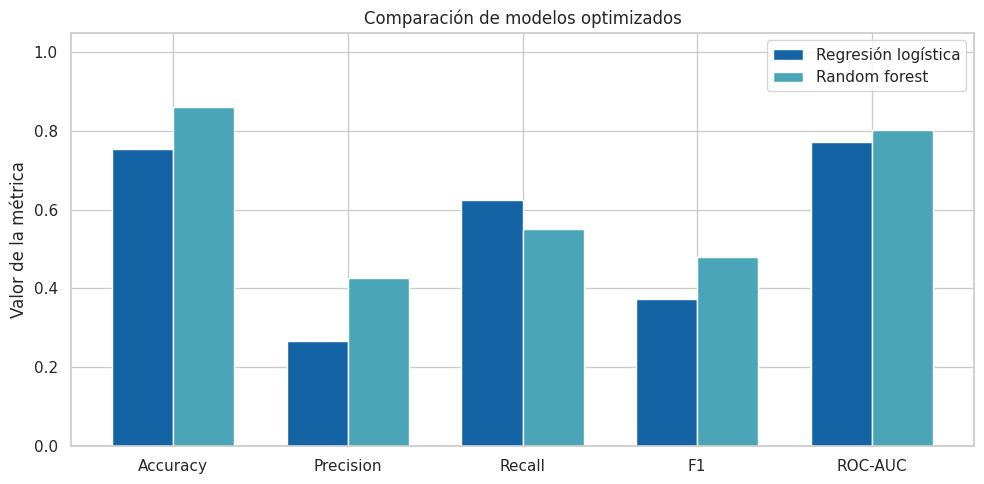

In [36]:
# Comparación visual
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

metricas_grafica = [
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"
]

valores_log = tabla_prueba.iloc[0][metricas_grafica].astype(float).values
valores_rf = tabla_prueba.iloc[1][metricas_grafica].astype(float).values

x = np.arange(len(metricas_grafica))
ancho = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - ancho/2,
    valores_log,
    ancho,
    label="Regresión logística",
    color="#1464A5"
)

plt.bar(
    x + ancho/2,
    valores_rf,
    ancho,
    label="Random forest",
    color="#49A5B7"
)

plt.xticks(x, metricas_grafica)
plt.ylabel("Valor de la métrica")
plt.title("Comparación de modelos optimizados")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

ruta_evidencias = Path(
    "/content/Actividad5-Bank-Marketing/evidencias"
)
ruta_evidencias.mkdir(parents=True, exist_ok=True)

plt.savefig(
    ruta_evidencias / "figura11_comparacion_modelos.png",
    dpi=160
)
plt.show()


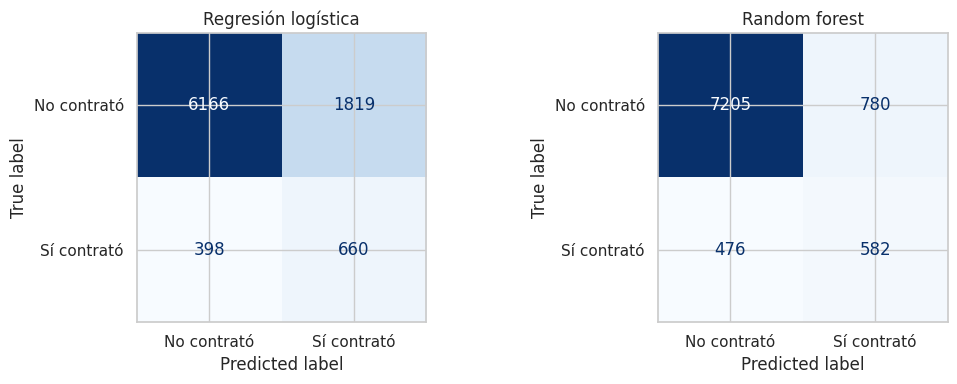


=== Regresión logística ===
Verdaderos negativos: 6166
Falsos positivos: 1819
Falsos negativos: 398
Verdaderos positivos: 660

=== Random forest ===
Verdaderos negativos: 7205
Falsos positivos: 780
Falsos negativos: 476
Verdaderos positivos: 582


In [37]:
# Matrices de confusión

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (nombre, y_pred) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No contrató", "Sí contrató"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(nombre)

plt.tight_layout()
plt.savefig(
    ruta_evidencias / "figura12_matrices_confusion.png",
    dpi=160
)
plt.show()

for nombre, y_pred in predicciones.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"\n=== {nombre} ===")
    print("Verdaderos negativos:", tn)
    print("Falsos positivos:", fp)
    print("Falsos negativos:", fn)
    print("Verdaderos positivos:", tp)


In [38]:
# Variabilidad en validación cruzada

print("=== VARIABILIDAD DE F1 INICIAL ===")

for _, fila in tabla_resultados.iterrows():
    print(
        f"{fila['Modelo']}: "
        f"F1 = {fila['f1']:.4f} "
        f"+/- {fila['f1_std']:.4f}"
    )

print("\n=== MEJORES F1 DE GRIDSEARCHCV ===")
print("Regresión logística:", round(grid_logistica.best_score_, 4))
print("Random forest:", round(grid_forest.best_score_, 4))


=== VARIABILIDAD DE F1 INICIAL ===
Regresión logística: F1 = 0.2749 +/- 0.0129
Random forest: F1 = 0.3271 +/- 0.0185

=== MEJORES F1 DE GRIDSEARCHCV ===
Regresión logística: 0.3726
Random forest: 0.4702


In [39]:
# Prueba estadística de McNemar

from scipy.stats import binomtest

pred_log = predicciones["Regresión logística"]
pred_rf = predicciones["Random forest"]

# Identificar predicciones correctas
correcto_log = pred_log == y_test.to_numpy()
correcto_rf = pred_rf == y_test.to_numpy()

# Casos donde solamente uno de los modelos acertó
solo_log = np.sum(correcto_log & ~correcto_rf)
solo_rf = np.sum(~correcto_log & correcto_rf)

# Prueba exacta de McNemar
discordantes = int(solo_log + solo_rf)

if discordantes > 0:
    p_valor = binomtest(
        int(solo_log),
        n=discordantes,
        p=0.5,
        alternative="two-sided"
    ).pvalue
else:
    p_valor = 1.0

print("=== PRUEBA DE McNEMAR ===")
print("Solo acertó regresión logística:", solo_log)
print("Solo acertó random forest:", solo_rf)
print("Valor p:", round(p_valor, 6))

if p_valor < 0.05:
    print("Diferencia estadísticamente significativa en los aciertos.")
else:
    print("No se detectó diferencia significativa en los aciertos.")


=== PRUEBA DE McNEMAR ===
Solo acertó regresión logística: 200
Solo acertó random forest: 1161
Valor p: 0.0
Diferencia estadísticamente significativa en los aciertos.


In [40]:
# Exportar evidencias

# Guardar métricas finales
tabla_prueba.to_csv(
    ruta_evidencias / "metricas_finales.csv",
    index=False
)

# Guardar resumen estadístico
resumen_estadistico = pd.DataFrame([{
    "solo_logistica": int(solo_log),
    "solo_random_forest": int(solo_rf),
    "discordantes": discordantes,
    "p_valor_mcnemar": p_valor
}])

resumen_estadistico.to_csv(
    ruta_evidencias / "comparacion_estadistica.csv",
    index=False
)

print("Resultados finales y análisis estadístico guardados.")


Resultados finales y análisis estadístico guardados.


In [41]:
# Instalar MLflow

%pip install -q mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1

In [42]:
# Verificar instalación

import mlflow
import mlflow.sklearn

print("MLflow instalado correctamente")
print("Versión:", mlflow.__version__)


MLflow instalado correctamente
Versión: 3.17.1


In [46]:
# Configuración de MLflow

import mlflow
from pathlib import Path

# Carpeta principal del proyecto
repo = Path("/content/Actividad5-Bank-Marketing")

# Configurar base de datos SQLite
ruta_db = repo / "mlflow.db"
tracking_uri = f"sqlite:///{ruta_db}"

mlflow.set_tracking_uri(tracking_uri)

# Carpeta para guardar modelos y artefactos
ruta_artefactos = repo / "mlartifacts"
ruta_artefactos.mkdir(parents=True, exist_ok=True)

# Nombre del experimento
nombre_experimento = "Actividad5_Bank_Marketing"

# Comprobar si el experimento ya existe
experimento = mlflow.get_experiment_by_name(
    nombre_experimento
)

if experimento is None:
    # Crear experimento con ubicación de artefactos
    experiment_id = mlflow.create_experiment(
        name=nombre_experimento,
        artifact_location=ruta_artefactos.resolve().as_uri()
    )
    print("Experimento creado:", experiment_id)
else:
    print("Experimento existente:", experimento.experiment_id)

# Seleccionar el experimento
mlflow.set_experiment(nombre_experimento)

print("\n=== CONFIGURACIÓN MLFLOW ===")
print("MLflow configurado correctamente")
print("Versión:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", nombre_experimento)


2026/10/16 23:54:41 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 23:54:41 INFO mlflow.store.db.utils: Updating database tables


Experimento creado: 1

=== CONFIGURACIÓN MLFLOW ===
MLflow configurado correctamente
Versión: 3.17.1
Tracking URI: sqlite:////content/Actividad5-Bank-Marketing/mlflow.db
Experimento: Actividad5_Bank_Marketing


In [55]:
#Registrar experimentos en MLflow

# ==================================================
# CELDA 31 - REGISTRO REPRODUCIBLE EN MLFLOW
# Actividad 5 - Universidad BBVA
# ==================================================

import mlflow
import mlflow.sklearn
import pandas as pd
from pathlib import Path
from mlflow.models import infer_signature

repo = Path("/content/Actividad5-Bank-Marketing")
evidencias = repo / "evidencias"

configuraciones = [
    {
        "nombre": "Regresion_Logistica_Optimizada",
        "grid": grid_logistica,
        "modelo": "Regresión logística"
    },
    {
        "nombre": "Random_Forest_Optimizado",
        "grid": grid_forest,
        "modelo": "Random forest"
    }
]

# Consultar ejecuciones existentes
experimento = mlflow.get_experiment_by_name(
    "Actividad5_Bank_Marketing"
)

runs_existentes = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

# Ejemplo para documentar entrada y salida
ejemplo_entrada = X_train.head(5).copy()

for config in configuraciones:

    nombre = config["nombre"]
    grid = config["grid"]
    nombre_modelo = config["modelo"]

    # Comprobar si ya existe una ejecución terminada
    registrado = False

    if not runs_existentes.empty:
        registrados = runs_existentes[
            (runs_existentes["tags.mlflow.runName"] == nombre) &
            (runs_existentes["status"] == "FINISHED")
        ]

        registrado = not registrados.empty

    if registrado:
        print("Ya registrado:", nombre)
        continue

    # Obtener modelo y métricas
    modelo = grid.best_estimator_

    fila = tabla_prueba.loc[
        tabla_prueba["Modelo"] == nombre_modelo
    ].iloc[0]

    firma = infer_signature(
        ejemplo_entrada,
        modelo.predict(ejemplo_entrada)
    )

    # Crear ejecución
    with mlflow.start_run(run_name=nombre):

        mlflow.set_tags({
            "proyecto": "Actividad 5",
            "dataset": "Bank Marketing UCI",
            "algoritmo": nombre_modelo,
            "fase": "modelo_optimizado",
            "random_state": "42"
        })

        # Parámetros
        mlflow.log_params(grid.best_params_)

        mlflow.log_params({
            "cv_folds": 5,
            "test_size": 0.20,
            "scoring_grid": "f1",
            "dataset_registros": 45211,
            "variables_predictoras": 15
        })

        # Métricas
        mlflow.log_metric(
            "f1_gridsearch_cv",
            float(grid.best_score_)
        )

        for metrica in [
            "Accuracy", "Precision",
            "Recall", "F1", "ROC-AUC"
        ]:
            nombre_metrica = (
                "test_" +
                metrica.lower().replace("-", "_")
            )

            mlflow.log_metric(
                nombre_metrica,
                float(fila[metrica])
            )

        # Tipos internos conocidos de nuestros modelos
        tipos_confiables = [
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree"
        ]

        # Registrar pipeline completo
        mlflow.sklearn.log_model(
            sk_model=modelo,
            name="modelo",
            input_example=ejemplo_entrada,
            signature=firma,
            skops_trusted_types=tipos_confiables
        )

        # Artefactos
        archivos = [
            "metricas_finales.csv",
            "comparacion_estadistica.csv",
            "figura11_comparacion_modelos.png",
            "figura12_matrices_confusion.png"
        ]

        for archivo in archivos:
            ruta = evidencias / archivo

            if ruta.exists():
                mlflow.log_artifact(
                    str(ruta),
                    artifact_path="evidencias"
                )

        print("Experimento registrado:", nombre)

print("\nRegistro de MLflow completado.")


Ya registrado: Regresion_Logistica_Optimizada
Ya registrado: Random_Forest_Optimizado

Registro de MLflow completado.


In [56]:
# Verificar los experimentos registrados

import mlflow

experimento = mlflow.get_experiment_by_name(
    "Actividad5_Bank_Marketing"
)

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

columnas = [
    "tags.mlflow.runName",
    "status",
    "metrics.test_accuracy",
    "metrics.test_precision",
    "metrics.test_recall",
    "metrics.test_f1",
    "metrics.test_roc_auc",
    "metrics.f1_gridsearch_cv"
]

print("=== EXPERIMENTOS REGISTRADOS ===")

display(
    runs.reindex(columns=columnas).round(4)
)

print("Total de ejecuciones:", len(runs))
print(
    "Ejecuciones finalizadas:",
    (runs["status"] == "FINISHED").sum()
)


=== EXPERIMENTOS REGISTRADOS ===


,tags.mlflow.runName,status,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc,metrics.f1_gridsearch_cv
0,Random_Forest_Optimizado,FINISHED,0.8611,0.4273,0.5501,0.4810,0.8031,0.4702
1,Random_Forest_Optimizado,FAILED,0.8611,0.4273,0.5501,0.4810,0.8031,0.4702
2,Regresion_Logistica_Optimizada,FINISHED,0.7548,0.2662,0.6238,0.3732,0.7722,0.3726
3,Random_Forest_Optimizado,FAILED,0.8611,0.4273,0.5501,0.4810,0.8031,0.4702
4,Regresion_Logistica_Optimizada,FINISHED,0.7548,0.2662,0.6238,0.3732,0.7722,0.3726
5,Random_Forest_Optimizado,FAILED,0.8611,0.4273,0.5501,0.4810,0.8031,0.4702
6,Regresion_Logistica_Optimizada,FINISHED,0.7548,0.2662,0.6238,0.3732,0.7722,0.3726
7,Regresion_Logistica_Optimizada,FAILED,0.7548,0.2662,0.6238,0.3732,0.7722,0.3726


Total de ejecuciones: 8
Ejecuciones finalizadas: 4


In [57]:
# VERIFICAR MODELOS EN MLFLOW

from mlflow import MlflowClient
import pandas as pd

cliente = MlflowClient()
experimento = mlflow.get_experiment_by_name(
    "Actividad5_Bank_Marketing"
)

ejecuciones = cliente.search_runs(
    experiment_ids=[experimento.experiment_id]
)

resumen = []

for run in ejecuciones:
    if run.info.status != "FINISHED":
        continue

    modelos = mlflow.search_logged_models(
        experiment_ids=[experimento.experiment_id],
        filter_string=f"source_run_id = '{run.info.run_id}'"
    )

    resumen.append({
        "Modelo": run.data.tags.get("mlflow.runName"),
        "Run ID": run.info.run_id[:12],
        "Estado": run.info.status,
        "Modelos registrados": len(modelos)
    })

display(pd.DataFrame(resumen))


,Modelo,Run ID,Estado,Modelos registrados
0,Random_Forest_Optimizado,ab7054f30953,FINISHED,1
1,Regresion_Logistica_Optimizada,6760dc9e5a63,FINISHED,1
2,Regresion_Logistica_Optimizada,4e8caabe3150,FINISHED,1
3,Regresion_Logistica_Optimizada,136059143c2e,FINISHED,1


In [60]:
# Iniciar el panel de MLflow

# CELDA 33 - REINICIAR MLFLOW UI

import subprocess
import time
from pathlib import Path

repo = Path("/content/Actividad5-Bank-Marketing")
tracking_uri = f"sqlite:///{repo / 'mlflow.db'}"

# Detener el servidor anterior si existe
if "servidor" in globals():
    if servidor.poll() is None:
        servidor.terminate()
        try:
            servidor.wait(timeout=10)
        except subprocess.TimeoutExpired:
            servidor.kill()
            servidor.wait()

# Iniciar un servidor nuevo en otro puerto
puerto_mlflow = 5001

log_servidor = open("/tmp/mlflow_ui_5001.log", "w")

servidor = subprocess.Popen(
    [
        "mlflow", "server",
        "--backend-store-uri", tracking_uri,
        "--host", "0.0.0.0",
        "--port", str(puerto_mlflow),
        "--allowed-hosts", "*",
        "--workers", "1"
    ],
    stdout=log_servidor,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("=== ESTADO DEL SERVIDOR ===")
print("Servidor activo:", servidor.poll() is None)

print("\nÚltimos mensajes:")
print(
    Path("/tmp/mlflow_ui_5001.log")
    .read_text(errors="replace")[-1500:]
)


=== ESTADO DEL SERVIDOR ===
Servidor activo: True

Últimos mensajes:
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: *.
2026/10/17 00:30:43 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/17 00:30:43 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check



In [61]:
# Visualizar MLflow

# CELDA 34 - ABRIR MLFLOW DESDE COLAB

from google.colab import output
from IPython.display import display, IFrame

url_mlflow = output.eval_js(
    "google.colab.kernel.proxyPort(5001)"
)

print("Nueva URL de MLflow:")
print(url_mlflow)

display(
    IFrame(
        src=url_mlflow,
        width="100%",
        height=700
    )
)


Nueva URL de MLflow:
https://5001-m-s-kkb-usw4a0-jfvywavvmj4i-a.us-west4-0.prod.colab.dev


In [62]:
# Respaldo completo de MLflow.

# CELDA 35 - RESPALDAR EXPERIMENTOS MLFLOW

import shutil
import sqlite3
import zipfile
from pathlib import Path
from google.colab import files

repo = Path("/content/Actividad5-Bank-Marketing")

# Detener servidor si sigue activo
if "servidor" in globals() and servidor.poll() is None:
    servidor.terminate()
    servidor.wait(timeout=15)

# Crear copia consistente de SQLite
copia_db = Path("/content/mlflow_respaldo.db")

with sqlite3.connect(str(repo / "mlflow.db")) as origen:
    with sqlite3.connect(str(copia_db)) as destino:
        origen.backup(destino)

# Crear ZIP con base de datos y artefactos
zip_salida = Path("/content/Actividad5_MLflow.zip")

with zipfile.ZipFile(
    zip_salida, "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    zipf.write(copia_db, "mlflow.db")

    artefactos = repo / "mlartifacts"

    if artefactos.exists():
        for archivo in artefactos.rglob("*"):
            if archivo.is_file():
                zipf.write(
                    archivo,
                    str(archivo.relative_to(repo))
                )

print("Respaldo creado:", zip_salida.name)
print("Tamaño (MB):", round(
    zip_salida.stat().st_size / (1024**2), 2
))

files.download(str(zip_salida))


Respaldo creado: Actividad5_MLflow.zip
Tamaño (MB): 13.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
# Crear el archivo train.py

%%writefile /content/Actividad5-Bank-Marketing/fuentes/train.py
# Actividad 5 - Universidad BBVA
# Entrenamiento y registro reproducible en MLflow

import argparse
import json
import sys
from pathlib import Path

import mlflow
import mlflow.sklearn
import pandas as pd
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


BASE = Path(__file__).resolve().parents[1]
DATOS = BASE / "datos" / "datos_limp" / "bank_limpio.csv"
EVIDENCIAS = BASE / "evidencias"


def ejecutar():
    EVIDENCIAS.mkdir(parents=True, exist_ok=True)

    # 1. Cargar y validar datos
    df = pd.read_csv(DATOS)
    assert "y" in df.columns
    assert "duration" not in df.columns
    assert df["y"].isin(["yes", "no"]).all()

    X = df.drop(columns=["y"])
    y = df["y"].map({"no": 0, "yes": 1})

    # 2. División estratificada
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20,
        stratify=y, random_state=42
    )

    numericas = X_train.select_dtypes(
        include="number"
    ).columns.tolist()

    categoricas = X_train.select_dtypes(
        exclude="number"
    ).columns.tolist()

    # 3. Pipelines
    prep_log = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ])

    prep_rf = ColumnTransformer([
        ("num", "passthrough", numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ])

    modelos = {
        "Regresion_Logistica_Optimizada": (
            Pipeline([
                ("preprocesamiento", prep_log),
                ("clasificador", LogisticRegression(
                    max_iter=1000, random_state=42
                ))
            ]),
            {
                "clasificador__C": [0.1, 1, 10],
                "clasificador__class_weight": [None, "balanced"]
            }
        ),
        "Random_Forest_Optimizado": (
            Pipeline([
                ("preprocesamiento", prep_rf),
                ("clasificador", RandomForestClassifier(
                    random_state=42, n_jobs=-1
                ))
            ]),
            {
                "clasificador__n_estimators": [100, 200],
                "clasificador__max_depth": [10, 20],
                "clasificador__min_samples_leaf": [1, 5],
                "clasificador__class_weight": [None, "balanced"]
            }
        )
    }

    # 4. MLflow con SQLite
    db = BASE / "mlflow.db"
    mlflow.set_tracking_uri(f"sqlite:///{db}")

    nombre_exp = "Actividad5_Bank_Marketing"
    existente = mlflow.get_experiment_by_name(nombre_exp)

    if existente is None:
        mlflow.create_experiment(
            nombre_exp,
            artifact_location=(BASE / "mlartifacts").resolve().as_uri()
        )

    mlflow.set_experiment(nombre_exp)

    cv = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    )

    resultados = []

    # 5. Entrenamiento, evaluación y registro
    for nombre, (pipeline, parametros) in modelos.items():
        print(f"\nEntrenando {nombre}", flush=True)

        grid = GridSearchCV(
            pipeline,
            parametros,
            scoring="f1",
            cv=cv,
            n_jobs=2,
            refit=True,
            error_score="raise"
        )

        grid.fit(X_train, y_train)

        modelo = grid.best_estimator_
        pred = modelo.predict(X_test)
        prob = modelo.predict_proba(X_test)[:, 1]

        metricas = {
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(
                y_test, pred, zero_division=0
            ),
            "recall": recall_score(
                y_test, pred, zero_division=0
            ),
            "f1": f1_score(
                y_test, pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(y_test, prob)
        }

        resultados.append({
            "modelo": nombre,
            "f1_cv": grid.best_score_,
            **metricas
        })

        ejemplo = X_train.head(5).copy()
        firma = infer_signature(ejemplo, modelo.predict(ejemplo))

        with mlflow.start_run(run_name=nombre):
            mlflow.set_tags({
                "proyecto": "Actividad 5",
                "dataset": "Bank Marketing UCI",
                "algoritmo": nombre
            })

            mlflow.log_params(grid.best_params_)
            mlflow.log_params({
                "cv_folds": 5,
                "test_size": 0.20,
                "random_state": 42,
                "scoring_grid": "f1"
            })

            mlflow.log_metric("f1_gridsearch_cv", grid.best_score_)

            for metrica, valor in metricas.items():
                mlflow.log_metric(f"test_{metrica}", valor)

            mlflow.sklearn.log_model(
                sk_model=modelo,
                name="modelo",
                input_example=ejemplo,
                signature=firma,
                skops_trusted_types=[
                    "sklearn.compose._column_transformer._RemainderColsList",
                    "sklearn.tree._tree.Tree"
                ]
            )

        print("Mejores parámetros:", grid.best_params_)
        print("F1 de prueba:", round(metricas["f1"], 4))

    # 6. Guardar comparación
    tabla = pd.DataFrame(resultados)
    tabla.to_csv(
        EVIDENCIAS / "metricas_train_script.csv",
        index=False
    )

    print("\n=== RESULTADOS FINALES ===")
    print(tabla.to_string(index=False))
    print("\nEntrenamiento y registro completados.")


if __name__ == "__main__":
    ejecutar()


Overwriting /content/Actividad5-Bank-Marketing/fuentes/train.py


In [65]:

from pathlib import Path

archivo = Path(
    "/content/Actividad5-Bank-Marketing/fuentes/train.py"
)

print("Archivo encontrado:", archivo.exists())
print("Tamaño:", archivo.stat().st_size, "bytes")

# Verificar sintaxis sin entrenar todavía
import py_compile
py_compile.compile(str(archivo), doraise=True)

print("Sintaxis Python correcta")


Archivo encontrado: True
Tamaño: 5975 bytes
Sintaxis Python correcta


In [66]:
# ejecutar train.py

# PRUEBA COMPLETA DEL SCRIPT train.py

import subprocess
import sys
from pathlib import Path

script = Path(
    "/content/Actividad5-Bank-Marketing/fuentes/train.py"
)

print("Iniciando entrenamiento independiente...")

resultado = subprocess.run(
    [sys.executable, str(script)],
    cwd=str(script.parent.parent),
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(resultado.stdout[-12000:])

print("\n=== VERIFICACIÓN FINAL ===")
print("Código de salida:", resultado.returncode)

if resultado.returncode == 0:
    print("Script ejecutado correctamente.")
else:
    print("Se detectó un error durante la ejecución.")


Iniciando entrenamiento independiente...

Entrenando Regresion_Logistica_Optimizada
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Mejores parámetros: {'clasificador__C': 1, 'clasificador__class_weight': 'balanced'}
F1 de prueba: 0.3732

Entrenando Random_Forest_Optimizado
/usr/local/lib/python

In [67]:
# Actualizar README.md

from pathlib import Path

repo = Path("/content/Actividad5-Bank-Marketing")

readme = """# Actividad 5 - Bank Marketing

## Descripción
Predicción de contratación de depósitos bancarios
mediante regresión logística y random forest.

Proyecto académico de Machine Learning y MLOps.

## Dataset
Fuente: UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/222/bank+marketing

Archivo original: bank-full.csv
Registros: 45,211
Variables originales: 17

## Preparación de datos
- Sin valores nulos de Pandas.
- Sin duplicados exactos originales.
- Exclusión de duration para evitar fuga de información.
- Conservación de unknown y pdays = -1.
- Dataset preparado: 45,211 registros y 16 columnas.

## Estructura del proyecto
- datos/datos_ini/: dataset original.
- datos/datos_limp/: dataset preparado.
- fuentes/datos_prep.py: limpieza reproducible.
- fuentes/train.py: entrenamiento y MLflow.
- fuentes/entrena.ipynb: notebook de Colab.
- evidencias/: gráficas y resultados.
- CHANGELOG.md: historial de modificaciones.

## Algoritmos
1. Regresión logística.
2. Random forest.

## Metodología
- División estratificada 80/20.
- StratifiedKFold de 5 particiones.
- GridSearchCV con F1 como métrica de selección.
- Evaluación con accuracy, precision, recall,
  F1 y ROC-AUC.
- Seguimiento de experimentos mediante MLflow.

## Requisitos
Python 3.13 y las dependencias de requirements.txt.

## Reproducción
Desde la carpeta raíz del proyecto:

1. Instalar dependencias:
   python -m pip install -r requirements.txt

2. Preparar datos:
   python fuentes/datos_prep.py

3. Entrenar y registrar experimentos:
   python fuentes/train.py

El entrenamiento puede tardar varios minutos.

## MLflow
El script genera una base de datos SQLite denominada
mlflow.db y registra los experimentos en:

Actividad5_Bank_Marketing

Para abrir el panel desde la carpeta raíz:

mlflow server --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000

Después abrir:
http://127.0.0.1:5000

El respaldo histórico de MLflow se entrega
por separado en el ZIP final.

## Resultados de prueba

| Modelo | F1 | ROC-AUC |
|---|---|---|
| Regresión logística | 0.3732 | 0.7722 |
| Random forest | 0.4810 | 0.8031 |

Random forest obtuvo el mejor F1 y ROC-AUC.

## Limitaciones
- Dataset histórico de campañas bancarias portuguesas.
- Clases desbalanceadas.
- No se garantiza generalización a otros bancos.
- Los modelos requieren validación adicional
  antes de cualquier uso operativo.
- Los artefactos serializados deben cargarse
  únicamente desde fuentes confiables.

## Repositorio
https://github.com/FernandoPTec/Actividad5-Bank-Marketing
"""

(repo / "README.md").write_text(
    readme, encoding="utf-8"
)

print("README.md actualizado correctamente")


README.md actualizado correctamente


In [68]:
# Actualizar CHANGELOG.md

from datetime import date

archivo = repo / "CHANGELOG.md"

nueva_version = """
## Versión 1.0.0 - Entrenamiento y evaluación final

### Incorporado
- Entrenamiento reproducible mediante train.py.
- Regresión logística y random forest.
- Optimización con GridSearchCV y cinco folds.
- Evaluación final con cinco métricas.
- Comparación estadística mediante McNemar.
- Registro de experimentos y modelos en MLflow.
- Almacenamiento de experimentos mediante SQLite.

### Resultados
- Regresión logística: F1 = 0.3732.
- Random forest: F1 = 0.4810.
- Random forest: ROC-AUC = 0.8031.
- Modelo seleccionado: random forest.

### Verificación
- Script train.py ejecutado independientemente.
- Código de salida: 0.
- Resultados reproducidos correctamente.
"""

contenido = archivo.read_text(encoding="utf-8")

if "## Versión 1.0.0" not in contenido:
    archivo.write_text(
        contenido + "\n" + nueva_version,
        encoding="utf-8"
    )

print("CHANGELOG.md actualizado correctamente")


CHANGELOG.md actualizado correctamente


In [69]:
# Actualizar requirements.txt

from importlib.metadata import version

bibliotecas = [
    "pandas",
    "numpy",
    "scikit-learn",
    "scipy",
    "matplotlib",
    "seaborn",
    "mlflow",
    "skops",
    "joblib",
    "requests"
]

dependencias = []

for biblioteca in bibliotecas:
    dependencias.append(
        f"{biblioteca}=={version(biblioteca)}"
    )

(repo / "requirements.txt").write_text(
    "\n".join(dependencias) + "\n",
    encoding="utf-8"
)

print("=== DEPENDENCIAS REGISTRADAS ===")
print("\n".join(dependencias))


=== DEPENDENCIAS REGISTRADAS ===
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
seaborn==0.13.2
mlflow==3.17.1
skops==0.16.0
joblib==1.6.0
requests==2.32.4
